In [134]:
import sys
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [135]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.5,speckle_window=70)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=80,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

In [136]:
def radial_stretch_from_point(img, stretch_factor, center):
    h, w = img.shape[:2]
    cx, cy = center

    # pixel grid
    y, x = np.indices((h, w), dtype=np.float32)

    # shift relative to chosen center
    dx = x - cx
    dy = y - cy

    # scale vectors
    scale = 1 / stretch_factor

    map_x = (cx + dx * scale).astype(np.float32)
    map_y = (cy + dy * scale).astype(np.float32)
    
    stretched = cv2.remap(
        img,
        map_x,
        map_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return stretched

In [170]:
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')
print(len(step))

51


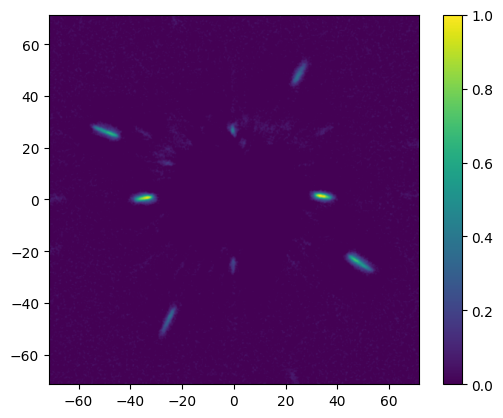

In [171]:
img = step[14]
hp = ADC.hpf(img,20)
hp = hp - ADC.hpf(hp,0.8)
hp[hp<0]=  0
img = ADC.crop_image(hp,mask_diam=35,extent=500)
imshow_field(img)
plt.colorbar()

In [173]:
search_size = 64
Z_cube = []
rel_rad_centers = []

for i, field in enumerate(step):
    hp = ADC.hpf(field,20)
    hp = hp - ADC.hpf(hp,0.8)
    hp[hp<0]=  0
    img = ADC.crop_image(hp,mask_diam=32,extent=500) #COI method

    Z = []
    psf = np.array(img.shaped)
    center = psf.shape[0]/2
    
    y, x = np.meshgrid(
        np.arange(center - search_size/2, center + search_size/2),
        np.arange(center - search_size/2, center + search_size/2),
        indexing="ij"
    )
    indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices
    
    for index in indices:
        psf_stretched = radial_stretch_from_point(psf,1.05,center=index)
        mse = np.sum((psf - psf_stretched)**2)
        Z.append(mse)

    Z = np.array(Z)
    a = np.unravel_index(Z.argmin(),y.shape)
    rel_rad_centers.append(a)

    Z_cube.append(np.reshape(Z,y.shape))

rel_rad_centerers = np.array(rel_rad_centers)
rel_rad_centerers = rel_rad_centerers - search_size/2

In [ ]:
print(rel_rad_centerers)

[[-16.  -5.]
 [-28.   7.]
 [-28.   8.]
 [-28.  10.]
 [-29.  11.]
 [-29.  13.]
 [-29.  15.]
 [-34.  25.]
 [-37.  28.]
 [-34.  29.]
 [-34.  30.]
 [-34.  31.]
 [-34.  33.]
 [-34.  34.]
 [-37.  45.]]


[13. 95.]
[-37.  45.]


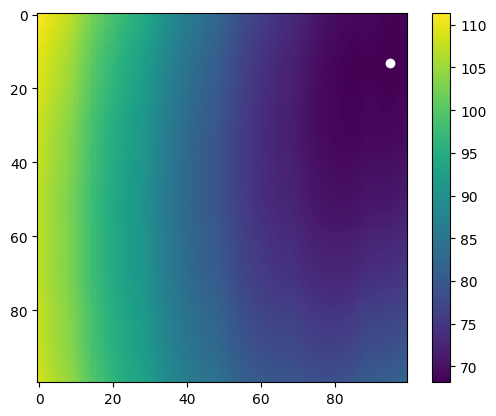

In [ ]:
n = 14
a = rel_rad_centerers[n] + search_size/2
plt.plot(a[1],a[0],'o',color='white',label='minimum MSE')
plt.imshow(Z_cube[n],origin='upper')
plt.colorbar()
print(a)
a = np.unravel_index(Z.argmin(),y.shape)
print(rel_rad_centerers[n])

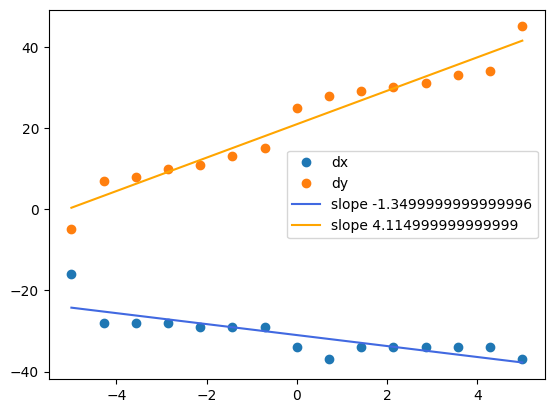

In [169]:
orientation_offsets = np.linspace(-5,5,15)
plt.plot(orientation_offsets,rel_rad_centerers[:,0],'o',label='dx')
plt.plot(orientation_offsets,rel_rad_centerers[:,1],'o',label='dy')

m1 , b1 = np.polyfit(orientation_offsets,rel_rad_centerers[:,0],deg=1)
linepoints = b1 + m1 * orientation_offsets
plt.plot(orientation_offsets, linepoints,label=f'slope {m1}',color='royalblue')

m2 , b2 = np.polyfit(orientation_offsets,rel_rad_centerers[:,1],deg=1)
linepoints = b2 + m2 * orientation_offsets
plt.plot(orientation_offsets, linepoints,label=f'slope {m2}',color='orange')

plt.legend()
# plt.xlabel('ADC co-rotation (°)')
# plt.title('Co-rotation, shear of 2°')


In [163]:
m1

np.float64(-0.6100000000000004)